#  This code is to create a heatmap (similar to Mulder et al. 2025 Fig 2G) using the gene signature published datasets and compared it to our DC2 subcluster signatures
Use only the signatures suggested by KR via email on 26.2.26
* DC2 - (Mulder DC2, Guimaraes_FCER1A, CXCL9
* DC3 - Mulder DC3, Guimaraes _DC3-CD14, DC4, CXCL8, AREG, CXCL4, Cheng FCN1, 
* IL1B DC- Mulder IL1B, Cheng DC2_IL1B
* ISG -  Mulder ISG, Moon ISG, Cheng DC2 ISG_15
* CD207 - Mulder CD207, Guimaraes-DC2_CD207, Cheng DC2-CD1A, Moon CD207
* LTB - Mulder LTB

In [2]:
#load packages I need
import os
import tools
import scanpy as sc
import pandas as pd
#import dandelion as ddl having trouble loading this
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns

In [3]:
from scipy.stats import zscore

In [4]:
import numpy as np

In [5]:
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/DEG_Heatmaps'

In [6]:
#show current directory 
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026'

In [7]:
os.listdir()

['20250617_AllDC_bbknn.h5ad',
 'NR_code',
 'newDC2annotations.h5ad',
 '20261003_DC2_bbknn_newannots.h5ad',
 'PubData_Heatmap.pdf',
 '.ipynb_checkpoints',
 'data_oc.h5ad',
 'Reference_mDC_Verse.rds',
 'NRclean_clustered2.h5ad',
 'alldc_ocdata.RDS',
 'AllDC_bbknndata.RDS',
 '20250629_DC2_bbknn_clustered2.h5ad',
 'figures',
 'NRclean_Raw_Data.h5ad']

## Import data with the DC2 subclusters

In [8]:
# Import renamed DC anndata
data_DC2 = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250629_DC2_bbknn_clustered2.h5ad')

In [9]:
data_DC2

AnnData object with n_obs × n_vars = 16643 × 2001
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'Guimaraes_DC2_FCER1A', 'Guimaraes_DC2_AREG', 'Guimaraes_Cheng_DC2_CD207/CD1A', 'Guimaraes_DC3_CD14', 'Guimaraes_DC4_FCGR3A', 'Guimaraes_DC_CXCL2', 'Cheng_DC2_CXCR4', 'Cheng_DC2_IL1B', 'Cheng_DC2_FCN1', 'Cheng_DC2_ISG15', 'Cheng_DC2_CXCL9', 

In [10]:
data_DC2.obs

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,...,2025-DC2-true_08_sub5,2025-DC2-true_08_sub5-1,cDC2A_sig,cDC2B_sig,cDC2_A-B,cDC2_Atlas_Subclusters,DC_CD207_Moon_sig,cDC2A_Minutti_sig,DC2_CD207_Gui_sig,DC2_CD1A_Cheng_sig
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143.000000,2659.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,...,0,0,0.147720,0.597550,cDC2B,1,-0.285166,0.061035,-0.227976,-0.075076
GSE215120_AM1_ACACTGATCCACTGGG-1,18333.000000,2845.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,...,0,0,-0.100811,0.181466,cDC2B,1,-0.263499,-0.025313,-0.229257,-0.267238
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581.000000,2182.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,...,0,0,-0.221879,-0.618129,cDC2B,1,-0.391576,-0.221879,-0.295809,-0.391943
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833.000000,2074.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,...,2,2,-0.227921,-0.107089,cDC2B,5,-0.240897,-0.227921,-0.263913,-0.379968
GSE215120_AM1_ACTTGTTTCTGAAAGA-1,7887.000000,1846.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.738684,skin,primary tumour,Acral Melanoma,...,2,2,-0.199067,0.283209,cDC2B,5,-0.106461,-0.199067,-0.207706,-0.095389
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGATCAGCAGTGTGCC,-9.194493,-8.535726,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA,2133.000000,ovary,primary tumour,HGSOC,...,"5,0","5,0",-0.258023,-0.668658,cDC2A,8,0.284868,-0.043808,-0.361723,0.363466
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGCGGCACAGAGGAAA,-9.025559,-8.786784,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA,2122.000000,ovary,primary tumour,HGSOC,...,2,2,-0.262817,-0.097966,cDC2B,5,-0.457705,-0.044300,-0.274982,-0.422830
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGGAGAGAGGCTTCCG,-8.552586,-8.416667,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA,2330.000000,ovary,primary tumour,HGSOC,...,2,2,-0.298592,-0.738670,cDC2B,5,-0.320366,-0.298592,-0.242780,-0.436415
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGTTGAGCAGCAAGAC,-9.298763,-8.526468,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA,1333.000000,ovary,primary tumour,HGSOC,...,2,2,0.194285,-0.248999,cDC2B,5,0.538345,0.410091,0.676352,0.435687


Isolate the cDC2 annotated cell subsets to be used 

In [11]:
data_DC2.obs["cDC2_Atlas_Subclusters"]

GSE215120_AM1_AAATGCCCAGAGCCAA-1                                         1
GSE215120_AM1_ACACTGATCCACTGGG-1                                         1
GSE215120_AM1_ACAGCCGCAAACCTAC-1                                         1
GSE215120_AM1_ACGTCAATCCGCATCT-1                                         5
GSE215120_AM1_ACTTGTTTCTGAAAGA-1                                         5
                                                                        ..
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGATCAGCAGTGTGCC    8
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGCGGCACAGAGGAAA    5
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGGAGAGAGGCTTCCG    5
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGTTGAGCAGCAAGAC    5
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TTCTTCCTCGCCACTT    1
Name: cDC2_Atlas_Subclusters, Length: 16643, dtype: category
Categories (10, object): ['1', '2', '3', '4', ..., '7', '8', '9', '10']

In [12]:
data_DC2.var

,name,mt,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells,highly_variable,means,dispersions,dispersions_norm,mean,std
KLHL17,KLHL17,False,8373,0.013762,0.013668,98.657975,8586.0,9.058005,153,True,0.012865,2.010730,1.506268,2.042335e-16,0.079397
HES4,HES4,False,70336,0.254356,0.226623,88.726543,158695.0,11.974746,2251,True,0.314010,1.823907,1.850645,7.977222e-16,0.426272
ISG15,ISG15,False,353813,6.551920,2.021802,43.290838,4087795.0,15.223517,8501,True,1.276740,2.825330,1.957977,6.678922e-15,0.893099
AGRN,AGRN,False,49296,0.102034,0.097158,92.098835,63660.0,11.061327,781,True,0.059248,1.493803,0.535962,5.094632e-16,0.173435
TNFRSF18,TNFRSF18,False,26091,0.103666,0.098637,95.818133,64678.0,11.077192,1131,True,0.139442,1.842845,1.191138,9.244143e-16,0.281637
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S100B,S100B,False,70333,0.709755,0.536350,88.727024,442822.0,13.000925,5197,True,1.869109,4.127680,3.565754,7.457219e-15,1.167012
MT-ATP8,MT-ATP8,True,268154,2.990670,1.383959,57.020266,1865903.0,14.439256,7849,True,1.698742,3.682156,2.476573,1.434491e-14,1.080200
MT-ND4L,MT-ND4L,True,459268,6.269149,1.983639,26.388506,3911372.0,15.179399,12261,True,2.432052,3.859601,1.239949,3.179106e-14,1.249763
MT-ND5,MT-ND5,True,544183,12.252872,2.584214,12.778326,7644665.0,15.849519,14819,True,2.629222,2.985325,0.868564,4.813657e-14,0.798346


## Read in the published gene lists
Looking at only the published genes of interest: DC2, DC3, ISG, CD207, LTB

In [13]:
# read in csv file with the Published gene data
gene_list = pd.read_csv("/scratch/user/uqlbukat/gene_sigs_papers_26226.csv", low_memory = False)

FileNotFoundError: [Errno 2] No such file or directory: '/scratch/user/uqlbukat/gene_sigs_papers_26226.csv'

In [ ]:
gene_list

,Mulder _DC2,Guimaraes_DC2_FCER1A,Cheng_DC2_CXCL9,Mulder_DC3,Guimaraes_DC3_CD14,Guimaraes_DC4_FCGR3A,Guimaraes_DC_CXCL8,Guimaraes_DC2_AREG,Cheng_DC2_CXCR4,Cheng_DC2_FCN1,Mulder_IL1B DC,Cheng_DC2_IL1B,Mulder_ISG DC,Moon _ISG DC,Cheng_DC2_ISG15,Mulder_CD207_DC,Guimaraes_DC2_CD207,Cheng_DC2_CD1A,Moon_CD207 DC,Mulder_LTB_DC
0,FCER1A,CD1C,CXCL9,S100A9,CD14,FCGR3A,CXCL8,AREG,CXCR4,CD163,G0S2,IL1B,ISG15,ISG15,ISG15,HLA-DQB2,CD207,CD207,CD1A,LTB
1,CD1C,FCER1A,CXCL10,C1QA,S100A9,FTL,CXCL2,NaN,DUSP4,CD14,CXCL8,TNF,IFI6,ISG20,IFI6,FCGBP,CD1A,CD1A,CD207,IL22RA2
2,CLEC10A,CLEC10A,IDO1,C1QB,S100A8,SERPINA1,NaN,NaN,FCER1A,FCN1,INSIG1,CCL3,IFI44L,CXCL9,IFIT1,CD207,NaN,S100B,FCGBP,LST1
3,TXNIP,NaN,NaN,C1QC,VCAN,NaN,NaN,NaN,NaN,S100A9,AREG,CCL4,IFIT3,CXCL10,IFITM1,CD1A,NaN,LTB,LTB,TNFRSF13C
4,JAML,NaN,NaN,S100A8,LYZ,NaN,NaN,NaN,NaN,S100A8,IL1B,NaN,IFIT1,IFIT1,IFIT2,S100B,NaN,NaN,SPI1,LINC01531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MANF,NaN,NaN,NaN,NaN
608,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NUCKS1,NaN,NaN,NaN,NaN
609,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRIM13,NaN,NaN,NaN,NaN
610,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PEBP1,NaN,NaN,NaN,NaN


In [ ]:
gene_list.shape

(612, 20)

In [ ]:
type(gene_list)

pandas.core.frame.DataFrame

Remove NAs from the gene_list

In [ ]:
# Remove all rows with any NaN values
clean_gene_list = gene_list.dropna()
print("\nDataFrame after dropping rows with any NaN:")
print(clean_gene_list)


DataFrame after dropping rows with any NaN:
  Mulder _DC2 Guimaraes_DC2_FCER1A Cheng_DC2_CXCL9 Mulder_DC3  \
0      FCER1A                 CD1C           CXCL9     S100A9   

  Guimaraes_DC3_CD14 Guimaraes_DC4_FCGR3A Guimaraes_DC_CXCL8  \
0               CD14               FCGR3A              CXCL8   

  Guimaraes_DC2_AREG Cheng_DC2_CXCR4 Cheng_DC2_FCN1 Mulder_IL1B DC  \
0               AREG           CXCR4          CD163           G0S2   

  Cheng_DC2_IL1B Mulder_ISG DC Moon _ISG DC Cheng_DC2_ISG15 Mulder_CD207_DC  \
0           IL1B         ISG15        ISG15           ISG15        HLA-DQB2   

  Guimaraes_DC2_CD207 Cheng_DC2_CD1A Moon_CD207 DC Mulder_LTB_DC  
0               CD207          CD207          CD1A           LTB  


In [ ]:
clean_gene_list = gene_list.fillna("")

In [ ]:
clean_gene_list.shape

(612, 20)

In [ ]:
clean_gene_list

,Mulder _DC2,Guimaraes_DC2_FCER1A,Cheng_DC2_CXCL9,Mulder_DC3,Guimaraes_DC3_CD14,Guimaraes_DC4_FCGR3A,Guimaraes_DC_CXCL8,Guimaraes_DC2_AREG,Cheng_DC2_CXCR4,Cheng_DC2_FCN1,Mulder_IL1B DC,Cheng_DC2_IL1B,Mulder_ISG DC,Moon _ISG DC,Cheng_DC2_ISG15,Mulder_CD207_DC,Guimaraes_DC2_CD207,Cheng_DC2_CD1A,Moon_CD207 DC,Mulder_LTB_DC
0,FCER1A,CD1C,CXCL9,S100A9,CD14,FCGR3A,CXCL8,AREG,CXCR4,CD163,G0S2,IL1B,ISG15,ISG15,ISG15,HLA-DQB2,CD207,CD207,CD1A,LTB
1,CD1C,FCER1A,CXCL10,C1QA,S100A9,FTL,CXCL2,,DUSP4,CD14,CXCL8,TNF,IFI6,ISG20,IFI6,FCGBP,CD1A,CD1A,CD207,IL22RA2
2,CLEC10A,CLEC10A,IDO1,C1QB,S100A8,SERPINA1,,,FCER1A,FCN1,INSIG1,CCL3,IFI44L,CXCL9,IFIT1,CD207,,S100B,FCGBP,LST1
3,TXNIP,,,C1QC,VCAN,,,,,S100A9,AREG,CCL4,IFIT3,CXCL10,IFITM1,CD1A,,LTB,LTB,TNFRSF13C
4,JAML,,,S100A8,LYZ,,,,,S100A8,IL1B,,IFIT1,IFIT1,IFIT2,S100B,,,SPI1,LINC01531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,,,,,,,,,,,,,,,,MANF,,,,
608,,,,,,,,,,,,,,,,NUCKS1,,,,
609,,,,,,,,,,,,,,,,TRIM13,,,,
610,,,,,,,,,,,,,,,,PEBP1,,,,


In [ ]:
## Create a data frame with all the gene lists in one
gene_df = gene_list.apply(lambda s: s.dropna().tolist()).to_frame().T
# gene_df.columns are your original columns
# gene_df.loc[0, "Column 1"] == ["gene 1", "gene 2"]

IndentationError: unexpected indent (1367317754.py, line 4)

In [46]:
gene_df

,Mulder _DC2,Guimaraes_DC2_FCER1A,Cheng_DC2_CXCL9,Mulder_DC3,Guimaraes_DC3_CD14,Guimaraes_DC4_FCGR3A,Guimaraes_DC_CXCL8,Guimaraes_DC2_AREG,Cheng_DC2_CXCR4,Cheng_DC2_FCN1,Mulder_IL1B DC,Cheng_DC2_IL1B,Mulder_ISG DC,Moon _ISG DC,Cheng_DC2_ISG15,Mulder_CD207_DC,Guimaraes_DC2_CD207,Cheng_DC2_CD1A,Moon_CD207 DC,Mulder_LTB_DC
0,"[FCER1A, CD1C, CLEC10A, TXNIP, JAML, FOS, ZFP3...","[CD1C, FCER1A, CLEC10A]","[CXCL9, CXCL10, IDO1]","[S100A9, C1QA, C1QB, C1QC, S100A8, CD14, APOE,...","[CD14, S100A9, S100A8, VCAN, LYZ, ANXA1]","[FCGR3A, FTL, SERPINA1]","[CXCL8, CXCL2]",[AREG],"[CXCR4, DUSP4, FCER1A]","[CD163, CD14, FCN1, S100A9, S100A8]","[G0S2, CXCL8, INSIG1, AREG, IL1B, CREM, PLAUR,...","[IL1B, TNF, CCL3, CCL4]","[ISG15, IFI6, IFI44L, IFIT3, IFIT1, LY6E, MX1,...","[ISG15, ISG20, CXCL9, CXCL10, IFIT1, IFIT3, IF...","[ISG15, IFI6, IFIT1, IFITM1, IFIT2]","[HLA-DQB2, FCGBP, CD207, CD1A, S100B, TACSTD2,...","[CD207, CD1A]","[CD207, CD1A, S100B, LTB]","[CD1A, CD207, FCGBP, LTB, SPI1, S100B]","[LTB, IL22RA2, LST1, TNFRSF13C, LINC01531, CEA..."


In [47]:
type (gene_df)

pandas.core.frame.DataFrame

## Create a heatmap with the gene lists and the DC data

In [48]:
gene_dict = gene_df.iloc[0].to_dict()
# keys: column names, values: lists of genes

In [49]:
gene_dict

{'Mulder _DC2': ['FCER1A',
  'CD1C',
  'CLEC10A',
  'TXNIP',
  'JAML',
  'FOS',
  'ZFP36L2',
  'RNASE6',
  'CD1D',
  'IFITM2',
  'CASP1',
  'IGSF6',
  'CACNA2D3',
  'FCER1G',
  'LST1',
  'MNDA',
  'CD33',
  'FCGR2B',
  'RNF130',
  'CLEC4A',
  'CFP',
  'CD52',
  'PLD4',
  'CEBPD',
  'IL1R2',
  'S100A4',
  'CD300A',
  'SAMHD1',
  'FXYD5',
  'LRRC25',
  'MEF2C',
  'IFITM3',
  'CD1E',
  'ARHGDIB',
  'CARD16',
  'DOK2',
  'MS4A6A',
  'HLA-DMB',
  'FYB',
  'PHACTR1',
  'GMFG',
  'RGS18',
  'PRAM1',
  'TSC22D3',
  'TNFAIP8L2',
  'POU2F2',
  'CORO1A',
  'LYZ',
  'PTAFR',
  'GAPT',
  'GLIPR1',
  'LIMD2',
  'STK17B',
  'SCIMP',
  'TRAF3IP3',
  'RAC2',
  'ENHO',
  'HLA-DMA',
  'MYO1F',
  'CSF3R',
  'IL18',
  'PLAC8',
  'FAM26F',
  'IFI16',
  'ANXA1',
  'C1ORF162',
  'NCF2',
  'FGR',
  'RGS2',
  'NDRG2',
  'CASP4',
  'AOAH',
  'AP1S2',
  'P2RY13',
  'CD37',
  'KCTD12',
  'HCLS1',
  'CNPY3',
  'CD53',
  'LILRB3',
  'CD302',
  'CPPED1',
  'LY86',
  'ETS2',
  'RACK1',
  'RNASET2',
  'PRELID1',
  'PDK

In [50]:
# Loop through each gene set and calculate the scores
for name, genes in gene_dict.items():
    sc.tl.score_genes(data_DC2, genes, score_name=name)

       'C19ORF43', 'C14ORF2', 'C14ORF166', 'PSMB8-AS1', 'C6ORF48', 'HLA-DRB6',
       'NAPSB', 'AMICA1', 'CCL3L3', 'RP11-1143G9.4'],
      dtype='object')
       'CCL3L3', 'SQRDL', 'LINC00936', 'TCEB2', 'CECR1', 'RP11-1143G9.4',
       'CXCL8', 'RP11-386I14.4'],
      dtype='object')
       'RP11-138A9.1', 'RP11-138A9.2', 'ADGRE2', 'CTD-3252C9.4', 'MMP12',
       'AIM1', 'ADGRE5', 'PRMT9', 'PAPD5', 'LRRC75A-AS1', 'MT-RNR2'],
      dtype='object')
       'CECR1', 'RARRES3', 'C1ORF162', 'C10orf54', 'CH17-373J23.1', 'CCL3L3'],
      dtype='object')
       'CFAP73', 'C6orf48', 'MT-RNR2', 'WBP5', 'FAM109A', 'C11orf31',
       'LINC01420', 'PLPP1', 'HN1', 'PRMT9', 'PVRL2', 'SELK', 'C20orf24',
       'OTUD6B-AS1', 'THAP9-AS1', 'CTA-29F11.1', 'GNB2L1', 'RTFDC1', 'RSRP1',
       'ATP5J', 'CCDC186', 'WAPL', 'RP1-313I6.12', 'CARD19', '44446', 'TIGAR',
       'FAM105A', 'OTULIN', 'C14orf166', 'WHSC1L1', 'RP3-460G2.2', 'ATPIF1',
       'MIR222HG', 'PDE4A'],
      dtype='object')
       'CTD-2006K23

In [51]:
data_DC2.obs.head()

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,...,Mulder_DC3,Guimaraes_DC_CXCL8,Mulder_IL1B DC,Mulder_ISG DC,Moon _ISG DC,Mulder_CD207_DC,Guimaraes_DC2_CD207,Cheng_DC2_CD1A,Moon_CD207 DC,Mulder_LTB_DC
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143.0,2659.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,...,0.466399,3.970372,0.662996,0.311982,0.320399,0.379513,-0.227976,-0.075076,-0.285166,0.912689
GSE215120_AM1_ACACTGATCCACTGGG-1,18333.0,2845.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,...,0.689576,2.933709,0.669877,0.509422,1.076773,0.461266,-0.229257,-0.267238,-0.263499,0.771065
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581.0,2182.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,...,0.251809,-0.290317,0.450068,0.325276,0.973349,0.428786,-0.295809,-0.391943,-0.391576,0.906236
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833.0,2074.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,...,0.331469,-0.348238,0.114173,0.386857,0.355561,0.396412,-0.263913,-0.379968,-0.240897,1.039778
GSE215120_AM1_ACTTGTTTCTGAAAGA-1,7887.0,1846.0,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.738684,skin,primary tumour,Acral Melanoma,...,0.320823,-0.303087,0.171427,0.390578,0.061395,0.319107,-0.207706,-0.095389,-0.106461,0.997843


## Check the structure of the data

In [52]:
data_DC2.obs_names.is_unique

True

In [53]:
data_DC2.obs_names[:5]

Index(['GSE215120_AM1_AAATGCCCAGAGCCAA-1', 'GSE215120_AM1_ACACTGATCCACTGGG-1',
       'GSE215120_AM1_ACAGCCGCAAACCTAC-1', 'GSE215120_AM1_ACGTCAATCCGCATCT-1',
       'GSE215120_AM1_ACTTGTTTCTGAAAGA-1'],
      dtype='object')

In [54]:
data_DC2.obs.shape

(16643, 75)

# Creating z-score heatmap using average gene expression

In [55]:
#Identify our cell subsets of interest
cell_subsets = ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']

In [56]:
#Published gene lists as a Python dict {signature_name: [genes]}
signatures = gene_dict
signatures

{'Mulder _DC2': ['FCER1A',
  'CD1C',
  'CLEC10A',
  'TXNIP',
  'JAML',
  'FOS',
  'ZFP36L2',
  'RNASE6',
  'CD1D',
  'IFITM2',
  'CASP1',
  'IGSF6',
  'CACNA2D3',
  'FCER1G',
  'LST1',
  'MNDA',
  'CD33',
  'FCGR2B',
  'RNF130',
  'CLEC4A',
  'CFP',
  'CD52',
  'PLD4',
  'CEBPD',
  'IL1R2',
  'S100A4',
  'CD300A',
  'SAMHD1',
  'FXYD5',
  'LRRC25',
  'MEF2C',
  'IFITM3',
  'CD1E',
  'ARHGDIB',
  'CARD16',
  'DOK2',
  'MS4A6A',
  'HLA-DMB',
  'FYB',
  'PHACTR1',
  'GMFG',
  'RGS18',
  'PRAM1',
  'TSC22D3',
  'TNFAIP8L2',
  'POU2F2',
  'CORO1A',
  'LYZ',
  'PTAFR',
  'GAPT',
  'GLIPR1',
  'LIMD2',
  'STK17B',
  'SCIMP',
  'TRAF3IP3',
  'RAC2',
  'ENHO',
  'HLA-DMA',
  'MYO1F',
  'CSF3R',
  'IL18',
  'PLAC8',
  'FAM26F',
  'IFI16',
  'ANXA1',
  'C1ORF162',
  'NCF2',
  'FGR',
  'RGS2',
  'NDRG2',
  'CASP4',
  'AOAH',
  'AP1S2',
  'P2RY13',
  'CD37',
  'KCTD12',
  'HCLS1',
  'CNPY3',
  'CD53',
  'LILRB3',
  'CD302',
  'CPPED1',
  'LY86',
  'ETS2',
  'RACK1',
  'RNASET2',
  'PRELID1',
  'PDK

In [57]:
data_DC2.var_names

Index(['KLHL17', 'HES4', 'ISG15', 'AGRN', 'TNFRSF18', 'TNFRSF4', 'PRKCZ',
       'MORN1', 'ACOT7', 'TNFRSF25',
       ...
       'COL18A1', 'PCBP3', 'COL6A1', 'COL6A2', 'DIP2A', 'S100B', 'MT-ATP8',
       'MT-ND4L', 'MT-ND5', 'MT-ND6'],
      dtype='object', length=2001)

## Compute average expression per cell subset

In [58]:
# Make a DataFrame of expression: genes x cells
# If X is sparse, toarray() is OK for moderate size; else keep sparse ops
expr = data_DC2.to_df()  # shape: (n_cells, n_genes)
expr.index = data_DC2.obs_names
expr.columns = data_DC2.var_names

In [59]:
# Add subset labels
meta = data_DC2.obs.copy()
meta["cell_id"] = meta.index

In [60]:
meta

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,...,Guimaraes_DC_CXCL8,Mulder_IL1B DC,Mulder_ISG DC,Moon _ISG DC,Mulder_CD207_DC,Guimaraes_DC2_CD207,Cheng_DC2_CD1A,Moon_CD207 DC,Mulder_LTB_DC,cell_id
GSE215120_AM1_AAATGCCCAGAGCCAA-1,17143.000000,2659.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.224990,skin,primary tumour,Acral Melanoma,...,3.970372,0.662996,0.311982,0.320399,0.379513,-0.227976,-0.075076,-0.285166,0.912689,GSE215120_AM1_AAATGCCCAGAGCCAA-1
GSE215120_AM1_ACACTGATCCACTGGG-1,18333.000000,2845.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.063656,skin,primary tumour,Acral Melanoma,...,2.933709,0.669877,0.509422,1.076773,0.461266,-0.229257,-0.267238,-0.263499,0.771065,GSE215120_AM1_ACACTGATCCACTGGG-1
GSE215120_AM1_ACAGCCGCAAACCTAC-1,10581.000000,2182.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.050846,skin,primary tumour,Acral Melanoma,...,-0.290317,0.450068,0.325276,0.973349,0.428786,-0.295809,-0.391943,-0.391576,0.906236,GSE215120_AM1_ACAGCCGCAAACCTAC-1
GSE215120_AM1_ACGTCAATCCGCATCT-1,9833.000000,2074.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.311909,skin,primary tumour,Acral Melanoma,...,-0.348238,0.114173,0.386857,0.355561,0.396412,-0.263913,-0.379968,-0.240897,1.039778,GSE215120_AM1_ACGTCAATCCGCATCT-1
GSE215120_AM1_ACTTGTTTCTGAAAGA-1,7887.000000,1846.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.738684,skin,primary tumour,Acral Melanoma,...,-0.303087,0.171427,0.390578,0.061395,0.319107,-0.207706,-0.095389,-0.106461,0.997843,GSE215120_AM1_ACTTGTTTCTGAAAGA-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGATCAGCAGTGTGCC,-9.194493,-8.535726,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA,2133.000000,ovary,primary tumour,HGSOC,...,-0.424353,0.140609,0.439940,0.501814,0.372002,-0.361723,0.363466,0.284868,1.147224,GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_...
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGCGGCACAGAGGAAA,-9.025559,-8.786784,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA,2122.000000,ovary,primary tumour,HGSOC,...,-0.228144,0.158465,0.416816,-0.127706,0.305917,-0.274982,-0.422830,-0.457705,1.073785,GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_...
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGGAGAGAGGCTTCCG,-8.552586,-8.416667,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA,2330.000000,ovary,primary tumour,HGSOC,...,-0.394456,0.185762,0.596062,0.725314,0.360627,-0.242780,-0.436415,-0.320366,1.052386,GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_...
GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA_TGTTGAGCAGCAAGAC,-9.298763,-8.526468,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-118_S1_CD45P_LEFT_ADNEXA,1333.000000,ovary,primary tumour,HGSOC,...,-0.215321,0.146892,0.143447,-0.167678,0.245234,0.676352,0.435687,0.538345,1.068027,GSE180661_HGSOC_SPECTRUM-OV-118_S1_CD45P_LEFT_...


In [61]:
# Restrict to relevant subsets
keep_cells = meta["cDC2_Atlas_Subclusters"].isin(cell_subsets)
expr_sub = expr.loc[keep_cells, :]
meta_sub = meta.loc[keep_cells, :]

In [68]:
# Compute mean expression per gene per subset
# groupby on new_subset_heatmap
expr_sub["cDC2_Atlas_Subclusters"] = meta_sub["cDC2_Atlas_Subclusters"].values
mean_expr_by_subset = (
    expr_sub.groupby("cDC2_Atlas_Subclusters")
    .mean()
    .T  # now: genes x subsets
)
mean_expr_by_subset

/scratch/temp/21658223/ipykernel_1117531/2585295737.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  expr_sub.groupby("cDC2_Atlas_Subclusters")


cDC2_Atlas_Subclusters,1,2,3,4,5,6,7,8,9,10
KLHL17,-0.024672,-0.055702,-0.039151,-0.061845,-0.002098,0.006391,0.012355,0.114928,0.010306,0.100196
HES4,0.259299,-0.043525,0.382425,-0.047362,-0.202774,-0.413089,0.055226,-0.245020,-0.103012,-0.355486
ISG15,0.062560,-0.276061,-0.296397,-0.227684,-0.015521,0.251539,-0.026198,0.252478,0.100101,-0.043954
AGRN,0.054253,-0.094946,0.019369,-0.082418,-0.068401,-0.009825,0.029050,-0.042986,0.013930,0.160105
TNFRSF18,0.176783,-0.089751,-0.142221,-0.092157,-0.072227,-0.224882,0.128518,-0.202006,-0.040771,0.017043
...,...,...,...,...,...,...,...,...,...,...
S100B,-0.108683,-0.317372,-0.222768,2.013190,-0.200649,-0.198447,0.059434,1.781199,1.540261,0.662790
MT-ATP8,-0.312010,0.006769,0.247647,-0.069830,-0.524178,0.320469,0.927030,-0.377933,0.227710,0.110466
MT-ND4L,-0.323737,-0.178494,-0.259493,-0.115445,-0.455595,0.340274,1.172553,-0.217048,0.397227,0.330416
MT-ND5,0.104099,-0.539223,-0.131828,-1.080030,0.104380,0.297733,0.030774,0.276456,-0.250242,0.282859


In [64]:
#Collapse to signature scores (mean expression of each gene list)

#Create matrix: rows = cell subsets, cols = signatures
subset_names = cell_subsets
sig_names = list(signatures.keys())
sig_names

['Mulder _DC2',
 'Guimaraes_DC2_FCER1A',
 'Cheng_DC2_CXCL9',
 'Mulder_DC3',
 'Guimaraes_DC3_CD14',
 'Guimaraes_DC4_FCGR3A',
 'Guimaraes_DC_CXCL8',
 'Guimaraes_DC2_AREG',
 'Cheng_DC2_CXCR4',
 'Cheng_DC2_FCN1',
 'Mulder_IL1B DC',
 'Cheng_DC2_IL1B',
 'Mulder_ISG DC',
 'Moon _ISG DC',
 'Cheng_DC2_ISG15',
 'Mulder_CD207_DC',
 'Guimaraes_DC2_CD207',
 'Cheng_DC2_CD1A',
 'Moon_CD207 DC',
 'Mulder_LTB_DC']

In [65]:
subset_names

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']

In [66]:
sig_mat = pd.DataFrame(
    index=subset_names,
    columns=sig_names,
    dtype=float
)

In [67]:
sig_mat

,Mulder _DC2,Guimaraes_DC2_FCER1A,Cheng_DC2_CXCL9,Mulder_DC3,Guimaraes_DC3_CD14,Guimaraes_DC4_FCGR3A,Guimaraes_DC_CXCL8,Guimaraes_DC2_AREG,Cheng_DC2_CXCR4,Cheng_DC2_FCN1,Mulder_IL1B DC,Cheng_DC2_IL1B,Mulder_ISG DC,Moon _ISG DC,Cheng_DC2_ISG15,Mulder_CD207_DC,Guimaraes_DC2_CD207,Cheng_DC2_CD1A,Moon_CD207 DC,Mulder_LTB_DC
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [69]:
for sig_name, genes in signatures.items():
    # Intersect with genes present in the object
    genes_in_data = list(set(genes).intersection(mean_expr_by_subset.index))
    if len(genes_in_data) == 0:
        print(f"No genes from {sig_name} found in data; skipping.")
        continue
    
    # mean expression of this signature per subset
    # mean_expr_by_subset: genes x subsets
    sig_values = mean_expr_by_subset.loc[genes_in_data].mean(axis=0)
    
    # Fill into sig_mat
    sig_mat.loc[:, sig_name] = sig_values.loc[subset_names].values

In [70]:
sig_mat

,Mulder _DC2,Guimaraes_DC2_FCER1A,Cheng_DC2_CXCL9,Mulder_DC3,Guimaraes_DC3_CD14,Guimaraes_DC4_FCGR3A,Guimaraes_DC_CXCL8,Guimaraes_DC2_AREG,Cheng_DC2_CXCR4,Cheng_DC2_FCN1,Mulder_IL1B DC,Cheng_DC2_IL1B,Mulder_ISG DC,Moon _ISG DC,Cheng_DC2_ISG15,Mulder_CD207_DC,Guimaraes_DC2_CD207,Cheng_DC2_CD1A,Moon_CD207 DC,Mulder_LTB_DC
1,-0.022455,-0.078409,-0.000511,0.239291,0.254695,0.316716,0.616479,0.410315,0.263925,0.239598,0.298133,0.468786,0.058456,0.065509,-0.072329,0.060645,-0.089846,-0.138960,-0.100034,-0.055304
2,-0.183681,-0.118614,-0.013959,-0.167020,-0.204093,-0.127724,-0.225841,-0.388707,-0.215793,-0.113227,-0.216670,-0.253139,-0.179559,-0.152903,-0.228317,-0.168826,-0.208457,-0.241152,-0.232479,-0.143908
3,-0.114017,-0.464230,-0.066471,-0.016535,-0.122356,-0.297672,0.058733,-0.063859,-0.053762,-0.088415,0.310978,-0.057711,-0.119781,-0.200373,-0.381852,0.047784,-0.207317,-0.226323,-0.208297,0.044750
4,-0.386940,-0.479634,0.065610,-0.256679,-0.246218,-0.279198,-0.311998,-0.784810,-0.501693,-0.182871,-0.306343,-0.409825,-0.280274,-0.162484,-0.196185,-0.043442,0.560464,1.085732,0.938691,0.055401
5,0.119286,0.166108,0.038042,-0.052026,0.017597,-0.037930,-0.229060,0.291073,0.187397,-0.015406,-0.110127,-0.083767,0.011199,-0.010690,-0.107989,-0.026464,-0.044316,-0.063212,-0.072937,0.001163
6,0.062250,0.467019,-0.220958,-0.151334,-0.154755,-0.108822,-0.449999,-0.813884,-0.343383,-0.162198,-0.378770,-0.451346,0.150388,0.100853,0.576811,-0.125667,-0.143542,-0.102631,-0.111637,-0.030442
7,0.124530,-0.129681,0.173412,-0.033532,-0.060946,-0.132491,-0.220468,0.102414,-0.099261,-0.052893,0.019906,-0.047538,-0.026901,0.013603,0.052287,0.051500,0.172469,0.089429,0.082816,0.008510
8,-0.009902,0.368276,0.135508,-0.198435,-0.257140,-0.193568,-0.399013,0.217009,-0.037795,-0.386245,-0.116518,-0.162874,0.010677,0.053355,0.163986,0.272598,1.305741,1.445300,1.361821,0.615295
9,-0.153708,-0.202703,0.089419,-0.288411,-0.368879,-0.345759,-0.418607,-0.288689,-0.340039,-0.380502,-0.213189,-0.291840,-0.150877,-0.078813,0.089854,0.237557,0.952098,1.414460,1.208289,0.831166
10,-0.038358,0.120205,0.000778,-0.123051,-0.204940,-0.220958,-0.369141,-0.410166,-0.152416,-0.236929,0.034954,-0.252027,0.040538,0.060255,0.166088,0.287522,1.388049,1.000483,1.212978,0.324631


## Z-score and plot heatmap in Python (pheatmap-style)

In [71]:
# Drop any all-NaN columns, if any signatures were skipped
sig_mat_clean = sig_mat.dropna(axis=1, how="all")
sig_mat_clean

,Mulder _DC2,Guimaraes_DC2_FCER1A,Cheng_DC2_CXCL9,Mulder_DC3,Guimaraes_DC3_CD14,Guimaraes_DC4_FCGR3A,Guimaraes_DC_CXCL8,Guimaraes_DC2_AREG,Cheng_DC2_CXCR4,Cheng_DC2_FCN1,Mulder_IL1B DC,Cheng_DC2_IL1B,Mulder_ISG DC,Moon _ISG DC,Cheng_DC2_ISG15,Mulder_CD207_DC,Guimaraes_DC2_CD207,Cheng_DC2_CD1A,Moon_CD207 DC,Mulder_LTB_DC
1,-0.022455,-0.078409,-0.000511,0.239291,0.254695,0.316716,0.616479,0.410315,0.263925,0.239598,0.298133,0.468786,0.058456,0.065509,-0.072329,0.060645,-0.089846,-0.138960,-0.100034,-0.055304
2,-0.183681,-0.118614,-0.013959,-0.167020,-0.204093,-0.127724,-0.225841,-0.388707,-0.215793,-0.113227,-0.216670,-0.253139,-0.179559,-0.152903,-0.228317,-0.168826,-0.208457,-0.241152,-0.232479,-0.143908
3,-0.114017,-0.464230,-0.066471,-0.016535,-0.122356,-0.297672,0.058733,-0.063859,-0.053762,-0.088415,0.310978,-0.057711,-0.119781,-0.200373,-0.381852,0.047784,-0.207317,-0.226323,-0.208297,0.044750
4,-0.386940,-0.479634,0.065610,-0.256679,-0.246218,-0.279198,-0.311998,-0.784810,-0.501693,-0.182871,-0.306343,-0.409825,-0.280274,-0.162484,-0.196185,-0.043442,0.560464,1.085732,0.938691,0.055401
5,0.119286,0.166108,0.038042,-0.052026,0.017597,-0.037930,-0.229060,0.291073,0.187397,-0.015406,-0.110127,-0.083767,0.011199,-0.010690,-0.107989,-0.026464,-0.044316,-0.063212,-0.072937,0.001163
6,0.062250,0.467019,-0.220958,-0.151334,-0.154755,-0.108822,-0.449999,-0.813884,-0.343383,-0.162198,-0.378770,-0.451346,0.150388,0.100853,0.576811,-0.125667,-0.143542,-0.102631,-0.111637,-0.030442
7,0.124530,-0.129681,0.173412,-0.033532,-0.060946,-0.132491,-0.220468,0.102414,-0.099261,-0.052893,0.019906,-0.047538,-0.026901,0.013603,0.052287,0.051500,0.172469,0.089429,0.082816,0.008510
8,-0.009902,0.368276,0.135508,-0.198435,-0.257140,-0.193568,-0.399013,0.217009,-0.037795,-0.386245,-0.116518,-0.162874,0.010677,0.053355,0.163986,0.272598,1.305741,1.445300,1.361821,0.615295
9,-0.153708,-0.202703,0.089419,-0.288411,-0.368879,-0.345759,-0.418607,-0.288689,-0.340039,-0.380502,-0.213189,-0.291840,-0.150877,-0.078813,0.089854,0.237557,0.952098,1.414460,1.208289,0.831166
10,-0.038358,0.120205,0.000778,-0.123051,-0.204940,-0.220958,-0.369141,-0.410166,-0.152416,-0.236929,0.034954,-0.252027,0.040538,0.060255,0.166088,0.287522,1.388049,1.000483,1.212978,0.324631


In [72]:
# Z-score across subsets for each signature (so you compare cell types per signature)
# axis=0 => z-score down rows; we want per column, so axis=0 with .apply on DataFrame
sig_z = sig_mat_clean.apply(zscore, axis=0, result_type="broadcast")

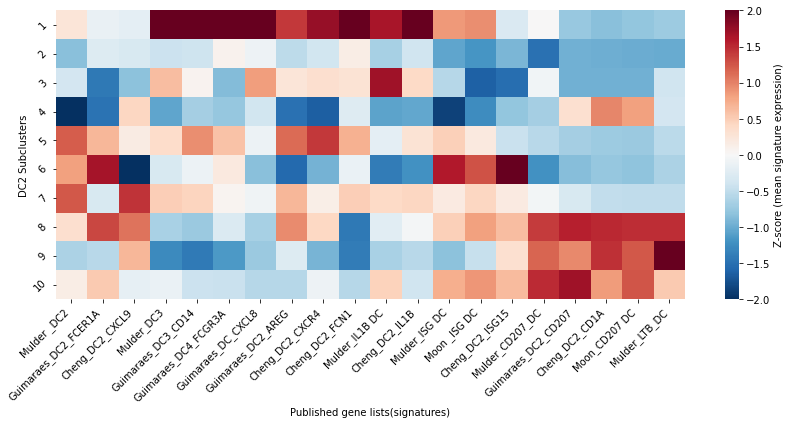

In [74]:
plt.figure(figsize=(len(sig_z.columns) * 0.4 + 4, len(sig_z.index) * 0.4 + 2))
sns.heatmap(
    sig_z,
    cmap="RdBu_r",
    center=0,
    vmin=-2,
    vmax=2,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Z-score (mean signature expression)"}
)
plt.xlabel("Published gene lists(signatures)")
plt.ylabel("DC2 Subclusters")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=45)
plt.tight_layout()
# Save the plot as a PDF file
plt.savefig('/scratch/user/uqlbukat/Output/PubData_DC2only26226_Heatmap.pdf')
plt.show()

## Overlay Published signatures on our DC2 atlas to see where the cells sit

Visualise the clusters in a UMAP

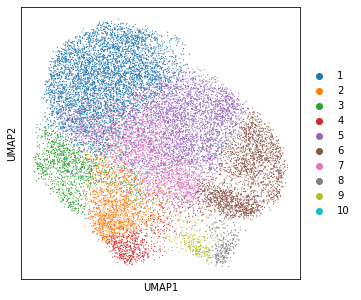

In [84]:
#export high res umap
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(data_DC2, color=["cDC2_Atlas_Subclusters"], size=5, title="")
#plt.savefig('/scratch/user/uqlbukat/Output/DC2Subcluster_umap.pdf')

   # Save the PDF within the context
plt.savefig("/scratch/user/uqlbukat/Output/DC2subclusterUmap.pdf", format='pdf')
plt.close() # Closes to free memory

Now visualise the expression of the signatures on the UMAP

In [76]:
gene_dict

{'Mulder _DC2': ['FCER1A',
  'CD1C',
  'CLEC10A',
  'TXNIP',
  'JAML',
  'FOS',
  'ZFP36L2',
  'RNASE6',
  'CD1D',
  'IFITM2',
  'CASP1',
  'IGSF6',
  'CACNA2D3',
  'FCER1G',
  'LST1',
  'MNDA',
  'CD33',
  'FCGR2B',
  'RNF130',
  'CLEC4A',
  'CFP',
  'CD52',
  'PLD4',
  'CEBPD',
  'IL1R2',
  'S100A4',
  'CD300A',
  'SAMHD1',
  'FXYD5',
  'LRRC25',
  'MEF2C',
  'IFITM3',
  'CD1E',
  'ARHGDIB',
  'CARD16',
  'DOK2',
  'MS4A6A',
  'HLA-DMB',
  'FYB',
  'PHACTR1',
  'GMFG',
  'RGS18',
  'PRAM1',
  'TSC22D3',
  'TNFAIP8L2',
  'POU2F2',
  'CORO1A',
  'LYZ',
  'PTAFR',
  'GAPT',
  'GLIPR1',
  'LIMD2',
  'STK17B',
  'SCIMP',
  'TRAF3IP3',
  'RAC2',
  'ENHO',
  'HLA-DMA',
  'MYO1F',
  'CSF3R',
  'IL18',
  'PLAC8',
  'FAM26F',
  'IFI16',
  'ANXA1',
  'C1ORF162',
  'NCF2',
  'FGR',
  'RGS2',
  'NDRG2',
  'CASP4',
  'AOAH',
  'AP1S2',
  'P2RY13',
  'CD37',
  'KCTD12',
  'HCLS1',
  'CNPY3',
  'CD53',
  'LILRB3',
  'CD302',
  'CPPED1',
  'LY86',
  'ETS2',
  'RACK1',
  'RNASET2',
  'PRELID1',
  'PDK

In [77]:
#mask data and use to calculate gene scores
adata_DC2 = data_DC2

In [78]:
adata_DC2

AnnData object with n_obs × n_vars = 16643 × 2001
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'Guimaraes_DC2_FCER1A', 'Guimaraes_DC2_AREG', 'Guimaraes_Cheng_DC2_CD207/CD1A', 'Guimaraes_DC3_CD14', 'Guimaraes_DC4_FCGR3A', 'Guimaraes_DC_CXCL2', 'Cheng_DC2_CXCR4', 'Cheng_DC2_IL1B', 'Cheng_DC2_FCN1', 'Cheng_DC2_ISG15', 'Cheng_DC2_CXCL9', 

In [79]:
# Loop through each gene set and calculate the scores
for name, genes in gene_dict.items():
    sc.tl.score_genes(adata_DC2, genes, score_name=name)

       'C19ORF43', 'C14ORF2', 'C14ORF166', 'PSMB8-AS1', 'C6ORF48', 'HLA-DRB6',
       'NAPSB', 'AMICA1', 'CCL3L3', 'RP11-1143G9.4'],
      dtype='object')
       'CCL3L3', 'SQRDL', 'LINC00936', 'TCEB2', 'CECR1', 'RP11-1143G9.4',
       'CXCL8', 'RP11-386I14.4'],
      dtype='object')
       'RP11-138A9.1', 'RP11-138A9.2', 'ADGRE2', 'CTD-3252C9.4', 'MMP12',
       'AIM1', 'ADGRE5', 'PRMT9', 'PAPD5', 'LRRC75A-AS1', 'MT-RNR2'],
      dtype='object')
       'CECR1', 'RARRES3', 'C1ORF162', 'C10orf54', 'CH17-373J23.1', 'CCL3L3'],
      dtype='object')
       'CFAP73', 'C6orf48', 'MT-RNR2', 'WBP5', 'FAM109A', 'C11orf31',
       'LINC01420', 'PLPP1', 'HN1', 'PRMT9', 'PVRL2', 'SELK', 'C20orf24',
       'OTUD6B-AS1', 'THAP9-AS1', 'CTA-29F11.1', 'GNB2L1', 'RTFDC1', 'RSRP1',
       'ATP5J', 'CCDC186', 'WAPL', 'RP1-313I6.12', 'CARD19', '44446', 'TIGAR',
       'FAM105A', 'OTULIN', 'C14orf166', 'WHSC1L1', 'RP3-460G2.2', 'ATPIF1',
       'MIR222HG', 'PDE4A'],
      dtype='object')
       'CTD-2006K23

In [80]:
colour_vars = gene_dict

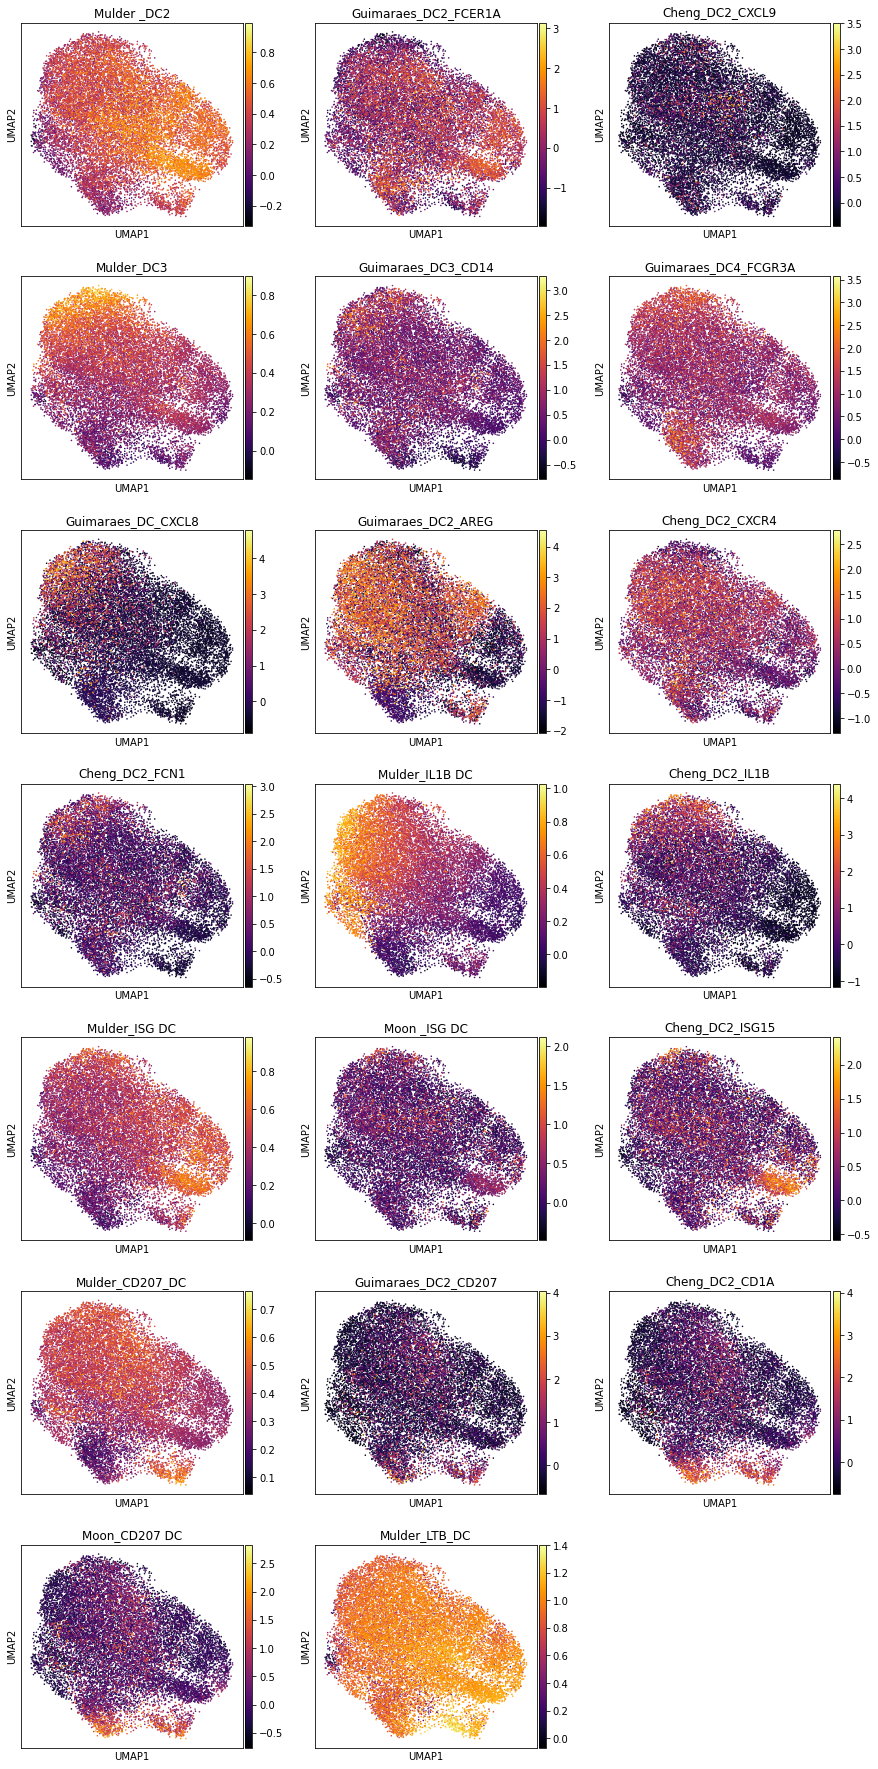

In [81]:
#plotting 
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(adata_DC2, color=colour_vars, ncols=3, size=10,
                cmap='inferno')
#plt.savefig('/scratch/user/uqlbukat/Output/PublishedSigs_DC2SubclusterOverlay.pdf')